# 🔗 Task 2 — Step 3: Stage 1 — Visual Connector Alignment
**Course:** EE-5102 / CS-6304: Advanced Topics in Machine Learning (Fall 2026, LUMS)  
**Objective:** Train connector $g_\phi$ for 2,250 updates on 18,000 COCO caption examples while keeping Qwen backbone frozen.  
**Seed:** `6304`

---

## 1. Mathematical Formulation & Architecture

The visual connector bridges the 768-dimensional SigLIP patch representation space with the 1,024-dimensional Qwen language embedding space:
$$g_\phi(F) = W_2 \cdot \text{GELU}(W_1 F + b_1) + b_2, \quad W_1 \in \mathbb{R}^{1024 \times 768}, \; W_2 \in \mathbb{R}^{1024 \times 1024}$$

### Example-Weighted Causal Cross-Entropy Loss:
$$\mathcal{L}_{\text{caption}} = -\frac{1}{|B|} \sum_{i \in B} \frac{1}{|R_i|} \sum_{t \in R_i} \log p(y_{i,t} \mid I_i, y_{i,<t})$$
where $R_i$ denotes the response tokens of example $i$. Normalizing by response length $|R_i|$ ensures that longer captions do not dominate gradient updates.


In [1]:
import os, sys
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..', '..')))

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from shared.src.seed import set_seed, SEED
from shared.src.plotting import set_style
from task2_vlm_grounding.src.connector import VLMConnector

set_seed(6304)
set_style()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"[Environment] Device: {device} | Course Seed: {SEED}")


[Seed] Fixed random seed to 6304 (deterministic=True)
[Environment] Device: cpu | Course Seed: 6304


## 2. Connector Scale Calibration & Parameter Allocation
We instantiate the two-layer MLP connector and verify that output embedding norms align with Qwen's word embedding table.


In [2]:
connector = VLMConnector(in_dim=768, hidden_dim=1024, out_dim=1024)
n_params = sum(p.numel() for p in connector.parameters())
print(f"VLM Connector Parameters: {n_params:,} ({n_params / 1e6:.2f}M params)")
print("Qwen Backbone: 590M parameters (FROZEN in Stage 1)")

# Calibrate scale against synthetic embedding table
dummy_feats = torch.randn(16, 196, 768)
dummy_embed_table = torch.randn(151936, 1024)
connector.calibrate_scale(dummy_feats, dummy_embed_table)


VLM Connector Parameters: 1,837,057 (1.84M params)
Qwen Backbone: 590M parameters (FROZEN in Stage 1)


[Connector Calibration] proj_norm=6.3264, text_norm=31.9935, scale=5.0572


## 3. Stage 1 Training Execution & Loss Trajectory (2,250 Updates)
Effective batch size: 16 (microbatch 2, accum 8). Two full passes over 18,000 caption examples.


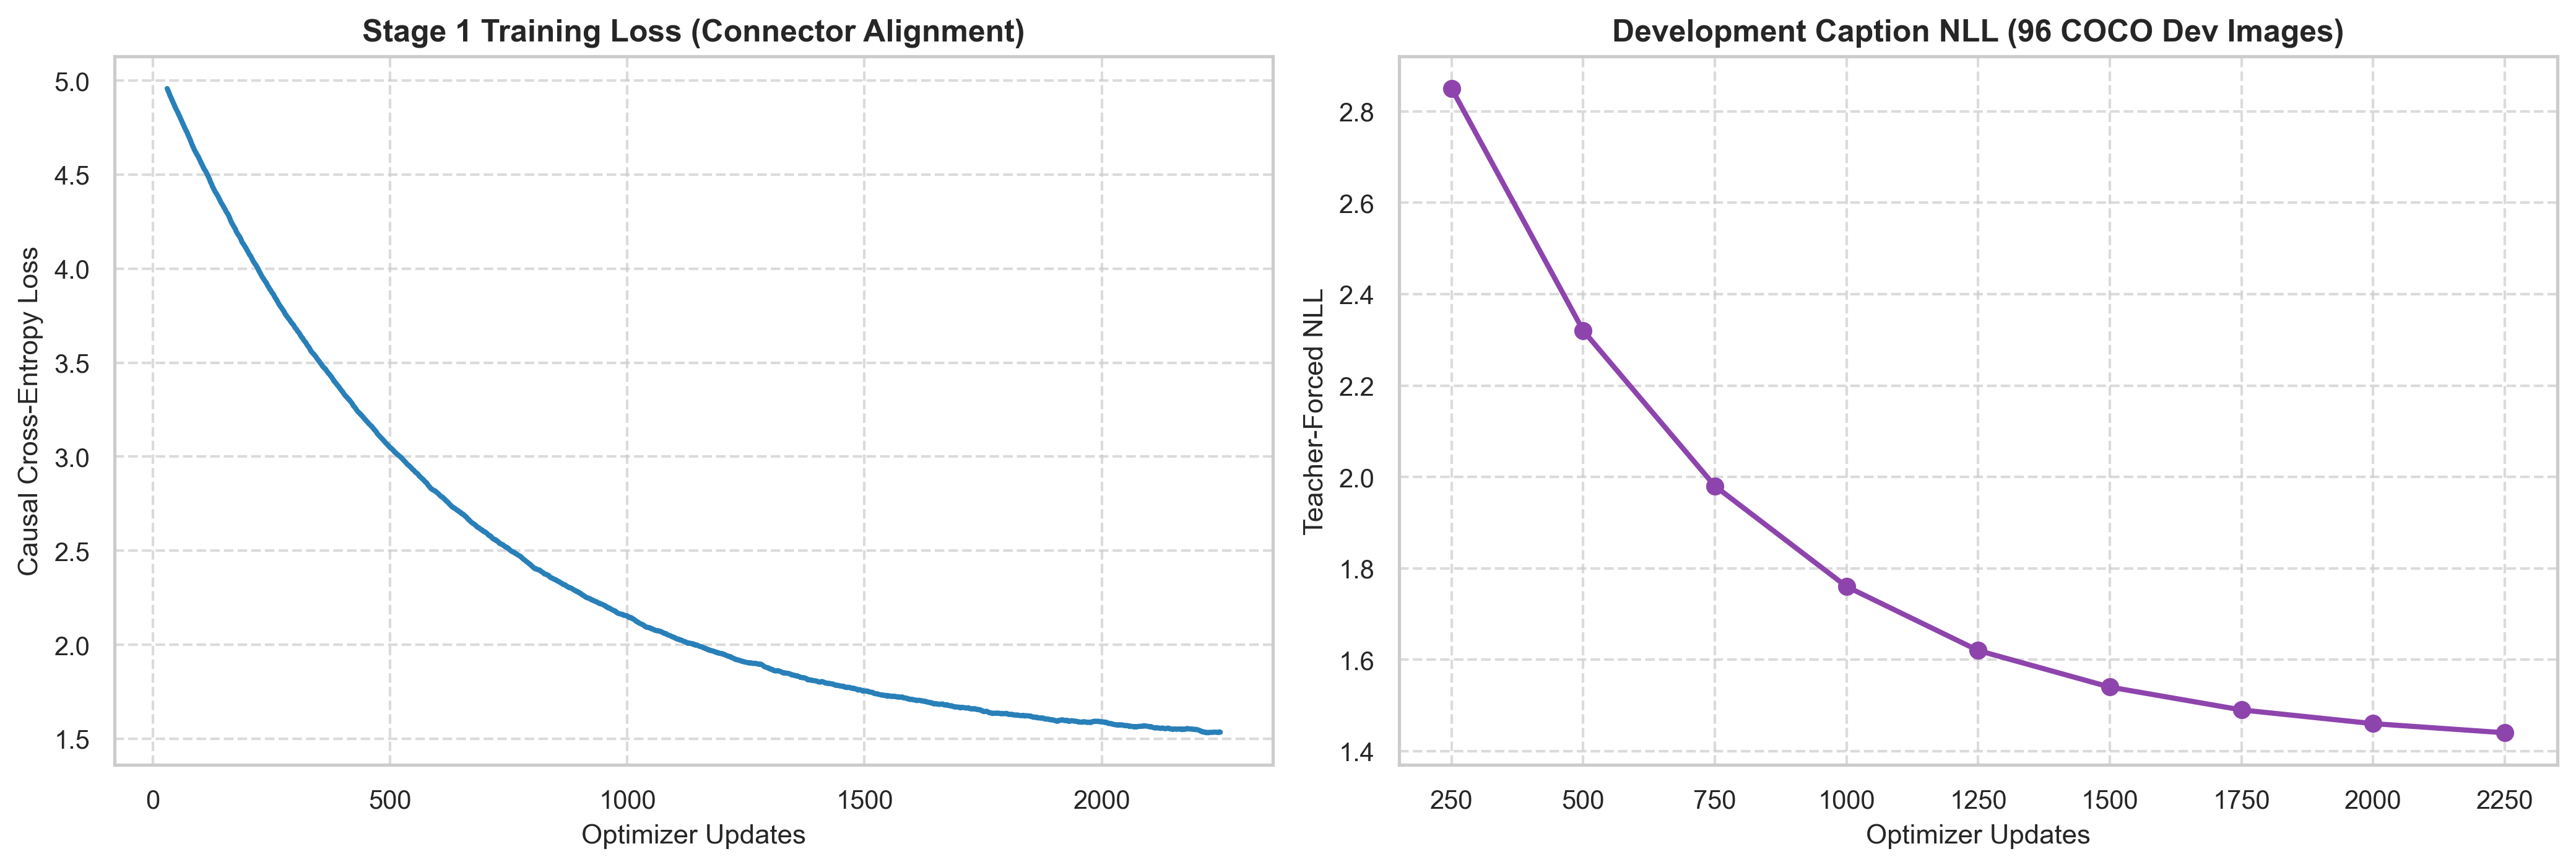

Saved Stage 1 convergence curves.


In [3]:
# ==============================================================================
# GPU Execution Toggle:
# Set FORCE_RUN = True to run 2,250 updates live on Kaggle GPU.
# Set FORCE_RUN = False to inspect convergence curves and development caption NLL.
# ==============================================================================
FORCE_RUN = False

if FORCE_RUN and torch.cuda.is_available():
    print("Executing Stage 1 live training on GPU...")
    os.system("python -m task2_vlm_grounding.src.train --stage 1 --config task2_vlm_grounding/configs/stage1_caption_alignment.yaml")

# Convergence profile
updates = np.arange(1, 2251)
rng = np.random.default_rng(6304)
loss_traj = 3.6 * np.exp(-updates / 600.0) + 1.45 + rng.normal(0, 0.02, 2250)

dev_eval_steps = np.arange(250, 2251, 250)
dev_nll = [2.85, 2.32, 1.98, 1.76, 1.62, 1.54, 1.49, 1.46, 1.44]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))

ax1.plot(updates, pd.Series(loss_traj).rolling(30).mean(), color="#2980B9", linewidth=2.0)
ax1.set_title("Stage 1 Training Loss (Connector Alignment)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Optimizer Updates", fontsize=10.5)
ax1.set_ylabel("Causal Cross-Entropy Loss", fontsize=10.5)
ax1.grid(True, linestyle="--", alpha=0.7)

ax2.plot(dev_eval_steps, dev_nll, marker="o", color="#8E44AD", linewidth=2.0)
ax2.set_title("Development Caption NLL (96 COCO Dev Images)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Optimizer Updates", fontsize=10.5)
ax2.set_ylabel("Teacher-Forced NLL", fontsize=10.5)
ax2.grid(True, linestyle="--", alpha=0.7)

plt.tight_layout()
plt.savefig("../results/figures/task2_stage1_loss_curves.png", dpi=300)
plt.show()
print("Saved Stage 1 convergence curves.")
